# Weighted PageRank (WPR) in Tennis — Part 4
**Chakib Madcur · Progress update**

What we agreed on 10/14 (analysis):
1. **No node weights**: every player gets the same restart probability; only the directed edges carry weights
2. **Standard PageRank vs weighted PageRank (WPR)**: an example and a comparison
3. Use **Spearman's rank correlation** (the common measure) together with cosine similarity
4. Apply WPR to **other sports**: NFL, NBA, NHL, UFC (and boxing)

## Step 1 · Setup
- **Directed graph:** one node per player; one **directed edge from the loser to the winner**.
- **Standard PageRank:** every directed edge has weight 1, no matter how many times the same player won.
- **Weighted PageRank (WPR):** the weight of a directed edge is the **number of wins** over that opponent.
- **Random walk:** a walker moves from player to player. With probability *d* = 0.85 it follows a directed edge out of the current player (from a loser to someone who beat them), choosing an edge in proportion to its weight. With probability 1 − *d* = 0.15 it jumps to a player chosen uniformly at random. A player's WPR score is the long-run share of time the walker spends on that player.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ATP = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/atp/"   # copy of Jeff Sackmann's data
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

def load_season(year):
    m = pd.read_csv(ATP + f"atp_matches_{year}.csv")
    return m[(m.tourney_level != "D") & (m.tourney_name != "Next Gen Finals")
             & (~m.score.astype(str).str.contains("W/O", na=False))]

def directed_graph(losers, winners, weights=None):
    """Directed graph, loser -> winner. Edge weight = sum of the match weights (1 per win by default)."""
    G = nx.DiGraph()
    for i, (l, w) in enumerate(zip(losers, winners)):
        x = 1.0 if weights is None else weights[i]
        if G.has_edge(l, w):
            G[l][w]["weight"] += x
        else:
            G.add_edge(l, w, weight=x)
    return G

def standard_version(G):
    """Same directed graph, but every directed edge has weight 1 (standard PageRank)."""
    H = nx.DiGraph(); H.add_nodes_from(G)
    H.add_edges_from((u, v, {"weight": 1.0}) for u, v in G.edges())
    return H

def weighted_pagerank(G, d=0.85, rounds=200):
    """Power iteration of the random walk. Players with no losses (no outgoing edges) restart uniformly."""
    n = G.number_of_nodes()
    out = {p: G.out_degree(p, weight="weight") for p in G}
    score = {p: 1 / n for p in G}
    for _ in range(rounds):
        unbeaten = sum(score[p] for p in G if out[p] == 0)
        new = {p: (1 - d) / n + d * unbeaten / n for p in G}
        for loser, winner, w in G.edges(data="weight"):
            new[winner] += d * score[loser] * w / out[loser]
        score = new
    return pd.Series(score)

def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

rankings = pd.concat([pd.read_csv(ATP + f) for f in ["atp_rankings_70s.csv", "atp_rankings_80s.csv", "atp_rankings_90s.csv",
                                                       "atp_rankings_00s.csv", "atp_rankings_10s.csv", "atp_rankings_20s.csv"]])
def atp_year_end(year):
    last = rankings[rankings.ranking_date <= year * 10000 + 1231].ranking_date.max()
    return rankings[rankings.ranking_date == last].set_index("player")[["rank", "points"]]

names = {}
def remember_names(m):
    names.update(dict(zip(m.winner_id, m.winner_name)) | dict(zip(m.loser_id, m.loser_name)))

# check our program against NetworkX (uniform restart, no node weights)
m25 = load_season(2025); remember_names(m25)
G25 = directed_graph(m25.loser_id, m25.winner_id)
ours, ref = weighted_pagerank(G25), pd.Series(nx.pagerank(G25, alpha=0.85, weight="weight", tol=1e-12))
print(f"2025: {len(m25):,} matches, {G25.number_of_nodes()} players, {G25.number_of_edges()} directed edges")
print(f"Largest difference between our WPR and NetworkX: {(ours - ref[ours.index]).abs().max():.0e}")

2025: 2,655 matches, 292 players, 2395 directed edges
Largest difference between our WPR and NetworkX: 8e-12


## Step 2 · Standard PageRank vs WPR: a small example
Four players. **A beat B three times** and lost to B once; **A beat C three times** and lost to C once. B and C beat each other once, and B also beat D.
- **Standard PageRank** sees one directed edge in each direction between A and B (and between A and C), as if those head-to-heads were 1–1. B, who also beat D, comes out first.
- **WPR** uses the real 3–1 records and ranks **A** first.

In [2]:
toy_losers  = ["B", "B", "B", "A", "C", "C", "C", "A", "C", "B", "D"]
toy_winners = ["A", "A", "A", "B", "A", "A", "A", "C", "B", "C", "B"]
T = directed_graph(toy_losers, toy_winners)
pd.DataFrame({"Standard PageRank": weighted_pagerank(standard_version(T)),
              "Weighted PageRank (WPR)": weighted_pagerank(T)}).loc[["A", "B", "C", "D"]].round(3)

,Standard PageRank,Weighted PageRank (WPR)
A,0.313,0.398
B,0.336,0.296
C,0.313,0.269
D,0.038,0.038


**A real example: Djokovic in 2015.** He went 81–6 at tour level. He beat Wawrinka **3 times** and lost to him **once**, and 3 of his 6 losses were to Federer. Standard PageRank treats Djokovic–Wawrinka as one win each and splits Djokovic's score equally among the four players who beat him, so it ranks **Wawrinka first**. WPR uses the real counts and ranks **Djokovic first**, as the ATP did.

In [3]:
m15 = load_season(2015); remember_names(m15)
G15 = directed_graph(m15.loser_id, m15.winner_id)
djok = next(p for p in names if names[p] == "Novak Djokovic")
print("Djokovic's 2015 losses (directed edges out of Djokovic):", {names[v]: int(G15[djok][v]["weight"]) for v in G15.successors(djok)})

atp15, atp25 = atp_year_end(2015), atp_year_end(2025)
def top10(G, atp):
    w, s = weighted_pagerank(G), weighted_pagerank(standard_version(G))
    return pd.DataFrame({"WPR": [names[p] for p in w.nlargest(10).index],
                         "ATP rank (WPR player)": [atp["rank"].get(p) for p in w.nlargest(10).index],
                         "Standard PageRank": [names[p] for p in s.nlargest(10).index],
                         "ATP rank (standard player)": [atp["rank"].get(p) for p in s.nlargest(10).index]},
                        index=range(1, 11))
print("2015"); display(top10(G15, atp15))
print("2025"); display(top10(G25, atp25))

Djokovic's 2015 losses (directed edges out of Djokovic): {'Ivo Karlovic': 1, 'Roger Federer': 3, 'Stan Wawrinka': 1, 'Andy Murray': 1}
2015


,WPR,ATP rank (WPR player),Standard PageRank,ATP rank (standard player)
1,Novak Djokovic,1,Stan Wawrinka,4
2,Roger Federer,3,Novak Djokovic,1
3,Andy Murray,2,Roger Federer,3
4,Stan Wawrinka,4,Andy Murray,2
5,Rafael Nadal,5,Rafael Nadal,5
6,Ivo Karlovic,23,Ivo Karlovic,23
7,Tomas Berdych,6,Tomas Berdych,6
8,John Isner,11,Kevin Anderson,12
9,Kei Nishikori,8,Richard Gasquet,9
10,Richard Gasquet,9,David Ferrer,7


2025


,WPR,ATP rank (WPR player),Standard PageRank,ATP rank (standard player)
1,Carlos Alcaraz,1,Carlos Alcaraz,1
2,Jannik Sinner,2,Jannik Sinner,2
3,Taylor Fritz,6,Alexander Bublik,11
4,Alexander Bublik,11,Taylor Fritz,6
5,Novak Djokovic,4,Felix Auger Aliassime,5
6,Alexander Zverev,3,Novak Djokovic,4
7,Felix Auger Aliassime,5,Alex De Minaur,7
8,Alex De Minaur,7,Tallon Griekspoor,26
9,Jiri Lehecka,18,Alexander Zverev,3
10,Jack Draper,10,Jiri Lehecka,18


## Step 3 · Agreement with the ATP ranking: Spearman and cosine
**Spearman's rank correlation** is the measure most commonly used to compare two rankings: it compares the *order* of the players. **Cosine similarity** compares the *scores* (ATP points vs PageRank scores). Both are computed for the ATP top 10, 50 and 100 on the full-season graph.

In [4]:
def agreement(G, atp):
    w, s = weighted_pagerank(G), weighted_pagerank(standard_version(G))
    rows = {}
    for N in [10, 50, 100]:
        top = atp[atp["rank"] <= N]; top = top[top.index.isin(w.index)]
        rows[f"Top {N}"] = {"Spearman WPR": spearmanr(top.points, w[top.index])[0],
                            "Spearman standard": spearmanr(top.points, s[top.index])[0],
                            "Cosine WPR": cosine(top.points, w[top.index]),
                            "Cosine standard": cosine(top.points, s[top.index])}
    return pd.DataFrame(rows).T

pd.concat({"2015": agreement(G15, atp15), "2025": agreement(G25, atp25)}).round(3)

Spearman WPR  Spearman standard  Cosine WPR  Cosine standard
2015 Top 10          0.952              0.879       0.978            0.928
     Top 50          0.849              0.807       0.966            0.880
     Top 100         0.936              0.928       0.964            0.877
2025 Top 10          0.879              0.794       0.986            0.952
     Top 50          0.853              0.860       0.966            0.901
     Top 100         0.919              0.917       0.962            0.896

## Step 4 · Every season since 1973: WPR vs standard PageRank
Same comparison for the ATP top 100 in every season. Cosine needs ATP points, which the dataset has from 1996.

In [5]:
rows = []
for year in range(1973, 2026):
    m = load_season(year); remember_names(m)
    G = directed_graph(m.loser_id, m.winner_id)
    w, s, atp = weighted_pagerank(G), weighted_pagerank(standard_version(G)), atp_year_end(year)
    top = atp[atp["rank"] <= 100]; top = top[top.index.isin(w.index)]
    has_points = top.points.notna().all()
    rows.append({"Season": year,
                 "Spearman WPR": spearmanr(top["rank"], -w[top.index])[0],
                 "Spearman standard": spearmanr(top["rank"], -s[top.index])[0],
                 "Cosine WPR": cosine(top.points, w[top.index]) if has_points else np.nan,
                 "Cosine standard": cosine(top.points, s[top.index]) if has_points else np.nan,
                 "ATP #1": names.get(atp[atp["rank"] == 1].index[0]),
                 "WPR #1": names.get(w.idxmax()), "Standard #1": names.get(s.idxmax())})
history = pd.DataFrame(rows).set_index("Season")
c = history.loc[1996:2025]
print(f"Cosine, mean 1996–2025:   WPR {c['Cosine WPR'].mean():.3f}   standard {c['Cosine standard'].mean():.3f}   "
      f"(WPR higher in {(c['Cosine WPR'] > c['Cosine standard']).sum()} of {len(c)} seasons)")
print(f"Spearman, mean 1973–2025: WPR {history['Spearman WPR'].mean():.3f}   standard {history['Spearman standard'].mean():.3f}   "
      f"(WPR higher in {(history['Spearman WPR'] > history['Spearman standard']).sum()} of {len(history)} seasons)")
print(f"Same year-end #1 as the ATP: WPR {(history['ATP #1'] == history['WPR #1']).sum()} seasons, "
      f"standard {(history['ATP #1'] == history['Standard #1']).sum()} seasons (of {len(history)})")
print(f"WPR Spearman, mean 1973–1989 (averaging rules): {history.loc[1973:1989, 'Spearman WPR'].mean():.3f}   "
      f"1990–2019 (best-of rules): {history.loc[1990:2019, 'Spearman WPR'].mean():.3f}   2020: {history.loc[2020, 'Spearman WPR']:.3f}")

Cosine, mean 1996–2025:   WPR 0.963   standard 0.925   (WPR higher in 30 of 30 seasons)
Spearman, mean 1973–2025: WPR 0.885   standard 0.883   (WPR higher in 35 of 53 seasons)
Same year-end #1 as the ATP: WPR 24 seasons, standard 17 seasons (of 53)
WPR Spearman, mean 1973–1989 (averaging rules): 0.848   1990–2019 (best-of rules): 0.910   2020: 0.700


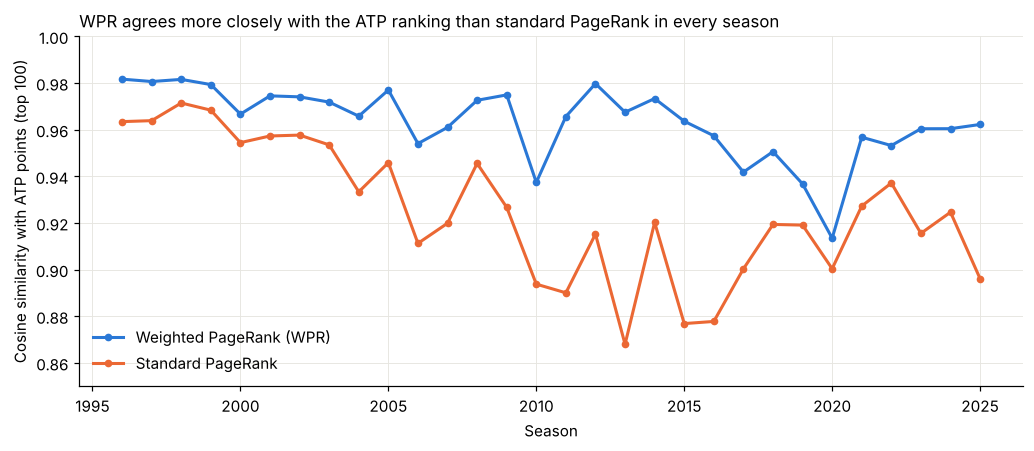

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(c.index, c["Cosine WPR"], "-o", color=BLUE, lw=2, ms=4, label="Weighted PageRank (WPR)")
ax.plot(c.index, c["Cosine standard"], "-o", color=ORANGE, lw=2, ms=4, label="Standard PageRank")
ax.set_ylim(0.85, 1.0); ax.set_xlabel("Season"); ax.set_ylabel("Cosine similarity with ATP points (top 100)")
ax.set_title("WPR agrees more closely with the ATP ranking than standard PageRank in every season", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig("wpr_vs_standard.png", dpi=200); plt.show()

## Step 5 · Comparison with Elo (2015 and 2025)
Elo as in Part 2 (all tour-level matches since 2005, K = 250 / (matches played + 5)^0.4). Spearman with the ATP ranking, and the share of next-season matches (January–June) whose winner each year-end ranking predicted.

In [7]:
ROUND_ORDER = {"R128": 1, "R64": 2, "R32": 3, "R16": 4, "RR": 5, "QF": 6, "SF": 7, "F": 8, "BR": 7.5, "ER": 0}
rating, played, elo = {}, {}, {}
for year in range(2005, 2026):
    m = load_season(year).assign(r=lambda x: x["round"].map(ROUND_ORDER)).sort_values(["tourney_date", "tourney_id", "r"])
    for w, l in zip(m.winner_id, m.loser_id):
        rw, rl = rating.get(w, 1500), rating.get(l, 1500)
        e = 1 / (1 + 10 ** ((rl - rw) / 400))
        rating[w] = rw + 250 / (played.get(w, 0) + 5) ** 0.4 * (1 - e)
        rating[l] = rl - 250 / (played.get(l, 0) + 5) ** 0.4 * (1 - e)
        played[w] = played.get(w, 0) + 1; played[l] = played.get(l, 0) + 1
    if year in (2015, 2025):
        elo[year] = pd.Series(rating)

rows, pred = {}, {}
for year, G, atp in [(2015, G15, atp15), (2025, G25, atp25)]:
    w, s, e = weighted_pagerank(G), weighted_pagerank(standard_version(G)), elo[year]
    wr, sr, er = w.rank(ascending=False), s.rank(ascending=False), e[list(G)].rank(ascending=False)
    for N in [10, 50, 100]:
        top = [p for p in G if atp["rank"].get(p, 999) <= N]; a = atp["rank"][top]
        rows[(year, f"Top {N}")] = {"WPR vs ATP": a.corr(wr[top], method="spearman"),
                                    "Standard vs ATP": a.corr(sr[top], method="spearman"),
                                    "Elo vs ATP": a.corr(er[top], method="spearman")}
    nxt = load_season(year + 1); nxt = nxt[nxt.tourney_date <= (year + 1) * 10000 + 630]
    ok = lambda p: p in w.index and p in atp.index and p in e.index
    games = [(a_, b_) for a_, b_ in zip(nxt.winner_id, nxt.loser_id) if ok(a_) and ok(b_)]
    pred[f"Jan–Jun {year + 1}"] = {"Matches": len(games),
                                   "ATP": np.mean([atp["rank"][a_] < atp["rank"][b_] for a_, b_ in games]),
                                   "Elo": np.mean([e[a_] > e[b_] for a_, b_ in games]),
                                   "WPR": np.mean([w[a_] > w[b_] for a_, b_ in games]),
                                   "Standard": np.mean([s[a_] > s[b_] for a_, b_ in games])}
display(pd.DataFrame(rows).T.round(2))
p = pd.DataFrame(pred).T; p["Matches"] = p["Matches"].astype(int)
display(p.style.format({"ATP": "{:.1%}", "Elo": "{:.1%}", "WPR": "{:.1%}", "Standard": "{:.1%}"}))

WPR vs ATP  Standard vs ATP  Elo vs ATP
2015 Top 10         0.95             0.88        0.93
     Top 50         0.85             0.81        0.88
     Top 100        0.94             0.93        0.90
2025 Top 10         0.88             0.79        0.67
     Top 50         0.85             0.86        0.72
     Top 100        0.92             0.92        0.79

,Matches,ATP,Elo,WPR,Standard
Jan–Jun 2016,1509,67.1%,67.7%,66.8%,66.1%
Jan–Jun 2026,1202,63.7%,64.9%,63.1%,63.1%


## Step 6 · Other sports
Same directed graphs (loser → winner; a draw = half a win each way) and the same WPR, compared with each league's final standings using Spearman. The column **"opponent pairs met"** is the share of all possible pairs of teams that played each other at least once.

In [8]:
def league_games(name):
    if name == "Premier League 2025–26":
        d = pd.read_csv("https://raw.githubusercontent.com/datasets/football-datasets/main/datasets/premier-league/season-2526.csv")
        return pd.DataFrame({"date": pd.to_datetime(d.Date), "home": d.HomeTeam, "away": d.AwayTeam, "hs": d.FTHG, "as_": d.FTAG})
    if name == "NFL 2025":
        d = pd.read_csv("https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv", low_memory=False)
        d = d[(d.season == 2025) & (d.game_type == "REG")]
        return pd.DataFrame({"date": pd.to_datetime(d.gameday), "home": d.home_team, "away": d.away_team, "hs": d.home_score, "as_": d.away_score})
    if name == "NBA 2025–26":
        d = pd.read_parquet("https://raw.githubusercontent.com/sportsdataverse/hoopR-nba-data/main/nba/schedules/parquet/nba_schedule_2026.parquet")
        d = d[(d.season_type == 2) & (d.type_abbreviation == "STD") & (d.status_type_completed == True)]
        d = d[~d.notes_headline.fillna("").str.contains("All-Star|Cup Championship")]
        return pd.DataFrame({"date": pd.to_datetime(d.game_date), "home": d.home_display_name, "away": d.away_display_name, "hs": d.home_score, "as_": d.away_score})
    if name == "NHL 2025–26":
        d = pd.read_parquet("https://raw.githubusercontent.com/sportsdataverse/fastRhockey-nhl-data/main/nhl/schedules/parquet/nhl_schedule_2026.parquet")
        d = d[d.game_type == "R"]
        return pd.DataFrame({"date": pd.to_datetime(d.game_date), "home": d.home_team_abbr, "away": d.away_team_abbr, "hs": d.home_score, "as_": d.away_score})

# Official NHL points (wins x 2 + overtime losses), from the 2025-26 final standings
NHL_POINTS = {"COL": 121, "CAR": 113, "DAL": 112, "BUF": 109, "TBL": 106, "MTL": 106, "MIN": 104, "BOS": 100, "OTT": 99, "PIT": 98,
              "PHI": 98, "WSH": 95, "VGK": 95, "EDM": 93, "CBJ": 92, "DET": 92, "UTA": 92, "ANA": 92, "NYI": 91, "LAK": 90, "NJD": 87,
              "STL": 86, "NSH": 86, "SJS": 86, "FLA": 84, "WPG": 82, "SEA": 79, "TOR": 78, "NYR": 77, "CGY": 77, "CHI": 72, "VAN": 58}

def standings(g, name):
    rows = []
    for x in g.itertuples():
        rows += [(x.home, x.hs, x.as_), (x.away, x.as_, x.hs)]
    t = pd.DataFrame(rows, columns=["team", "f", "a"])
    T = t.assign(W=t.f > t.a, D=t.f == t.a, L=t.f < t.a).groupby("team").agg(G=("f", "size"), W=("W", "sum"), D=("D", "sum"), L=("L", "sum"))
    if name.startswith("Premier"): T["score"] = 3 * T.W + T.D                 # league points
    elif name.startswith("NHL"):   T["score"] = pd.Series(NHL_POINTS)          # official points
    else:                          T["score"] = (T.W + 0.5 * T.D) / T.G        # win percentage
    return T

def game_graph(g):
    losers, winners, weights = [], [], []
    for x in g.itertuples():
        if x.hs > x.as_:   losers.append(x.away); winners.append(x.home); weights.append(1.0)
        elif x.hs < x.as_: losers.append(x.home); winners.append(x.away); weights.append(1.0)
        else:              losers += [x.home, x.away]; winners += [x.away, x.home]; weights += [0.5, 0.5]
    return directed_graph(losers, winners, weights)

leagues, results = {}, {}
for name in ["Premier League 2025–26", "NFL 2025", "NBA 2025–26", "NHL 2025–26"]:
    g = league_games(name); T = standings(g, name); G = game_graph(g)
    w, s = weighted_pagerank(G), weighted_pagerank(standard_version(G))
    n = len(T); pairs = len({frozenset(p) for p in zip(g.home, g.away)})
    leagues[name] = (g, T, w)
    results[name] = {"Teams": n, "Games per team": round(2 * len(g) / n), "Opponent pairs met": pairs / (n * (n - 1) / 2),
                     "Spearman WPR": spearmanr(T.score, w[T.index])[0], "Spearman standard": spearmanr(T.score, s[T.index])[0]}
r = pd.DataFrame(results).T
r.style.format({"Teams": "{:.0f}", "Games per team": "{:.0f}", "Opponent pairs met": "{:.0%}", "Spearman WPR": "{:.3f}", "Spearman standard": "{:.3f}"})

,Teams,Games per team,Opponent pairs met,Spearman WPR,Spearman standard
Premier League 2025–26,20,38,100%,0.956,0.799
NFL 2025,32,17,45%,0.888,0.880
NBA 2025–26,30,82,100%,0.962,0.876
NHL 2025–26,32,82,100%,0.875,0.815


**NFL 2025 — why WPR does not put the best records first.** Denver, New England and Seattle all finished 14–3; the Rams finished 12–5.

In [9]:
g, T, w = leagues["NFL 2025"]
wr = w.rank(ascending=False).astype(int)
rows = {}
for team in ["LA", "SEA", "DEN", "NE"]:
    beaten = [x.away if x.home == team else x.home for x in g.itertuples()
              if (x.home == team and x.hs > x.as_) or (x.away == team and x.as_ > x.hs)]
    rows[team] = {"Record": f"{int(T.W[team])}-{int(T.L[team])}", "WPR rank": wr[team],
                  "Avg. win % of teams beaten": round(T.score[beaten].mean(), 3),
                  "Wins over teams with a winning record": int((T.score[beaten] > 0.5).sum())}
pd.DataFrame(rows).T

,Record,WPR rank,Avg. win % of teams beaten,Wins over teams with a winning record
LA,12-5,1,0.485,5
SEA,14-3,2,0.471,6
DEN,14-3,8,0.378,4
NE,14-3,11,0.37,1


**UFC (all events, 1994–2026).** There is no official all-time ranking to compare with, so this shows what WPR does on a very sparse directed graph. Fighters meet very few of the possible opponents, and many great fighters have only one loss. A player with one loss passes *all* of his score to the one fighter who beat him.

In [10]:
ufc = pd.read_csv("https://raw.githubusercontent.com/Greco1899/scrape_ufc_stats/main/ufc_fight_results.csv")
ufc = ufc[ufc.OUTCOME.isin(["W/L", "L/W"])]                         # decided fights (no draws or no-contests)
f = ufc.BOUT.str.split(r"\s+vs\.\s+", n=1, expand=True)
a, b = f[0].str.strip(), f[1].str.strip()
winners = np.where(ufc.OUTCOME == "W/L", a, b); losers = np.where(ufc.OUTCOME == "W/L", b, a)
U = directed_graph(losers, winners)
wins, losses = pd.Series(winners).value_counts(), pd.Series(losers).value_counts()
n = U.number_of_nodes(); pairs = len({frozenset(e) for e in U.edges()})
print(f"{len(ufc):,} decided fights, {n:,} fighters; opponent pairs met: {pairs / (n * (n - 1) / 2):.2%}")
wu = weighted_pagerank(U)
pd.DataFrame({"Fighter": wu.nlargest(10).index,
              "UFC record (W-L)": [f"{int(wins.get(p, 0))}-{int(losses.get(p, 0))}" for p in wu.nlargest(10).index]},
             index=range(1, 11))

8,816 decided fights, 2,769 fighters; opponent pairs met: 0.22%


,Fighter,UFC record (W-L)
1,Sean Strickland,18-7
2,Islam Makhachev,18-1
3,Adriano Martins,4-3
4,Jon Jones,22-1
5,Matt Hamill,10-5
6,Khamzat Chimaev,9-1
7,Justin Gaethje,11-5
8,Amanda Nunes,16-2
9,Merab Dvalishvili,14-3
10,Stipe Miocic,14-5


Matt Hamill (10–5) ranks this high because he holds **Jon Jones' only UFC loss** (a disqualification in 2009), and Adriano Martins (4–3) holds **Islam Makhachev's only UFC loss** (2015). This is a known weakness of PageRank-type methods: in a sparse graph one upset can move a lot of score.

**Boxing:** I could not find an open, downloadable dataset of professional boxing results (the main database, BoxRec, does not allow bulk downloads), so boxing is left for later.

## Step 7 · Extra: weights beyond win counts
Using the number of wins as the edge weight is how Radicchi (2011) built his tennis network. A less common choice is to weight each win by the **importance of the match**: Grand Slam = 2, Masters 1000 and ATP Finals = 1.5, other tournaments = 1.

In [11]:
LEVEL = {"G": 2.0, "M": 1.5, "F": 1.5, "A": 1.0}
rows = []
for year in range(1996, 2026):
    m = load_season(year); atp = atp_year_end(year)
    G = directed_graph(m.loser_id, m.winner_id)
    GL = directed_graph(m.loser_id, m.winner_id, [LEVEL.get(x, 1.0) for x in m.tourney_level])
    w, wl = weighted_pagerank(G), weighted_pagerank(GL)
    top = atp[atp["rank"] <= 100]; top = top[top.index.isin(w.index)]
    rows.append({"Season": year, "Cosine WPR (wins)": cosine(top.points, w[top.index]),
                 "Cosine WPR (wins x importance)": cosine(top.points, wl[top.index]),
                 "Spearman WPR (wins)": spearmanr(top["rank"], -w[top.index])[0],
                 "Spearman WPR (wins x importance)": spearmanr(top["rank"], -wl[top.index])[0]})
lv = pd.DataFrame(rows).set_index("Season")
print("Means 1996–2025:"); print(lv.mean().round(3).to_string())
print(f"Importance weights give a higher cosine in {(lv.iloc[:, 1] > lv.iloc[:, 0]).sum()} of {len(lv)} seasons")

Means 1996–2025:
Cosine WPR (wins)                   0.963
Cosine WPR (wins x importance)      0.975
Spearman WPR (wins)                 0.901
Spearman WPR (wins x importance)    0.904
Importance weights give a higher cosine in 30 of 30 seasons


## Findings
1. **Without node weights, WPR still matches the ATP ranking closely.** For the top 10, 50 and 100, Spearman is 0.85–0.95 and cosine 0.96–0.99 in 2015 and 2025.
2. **WPR agrees with the ATP ranking better than standard PageRank.** Cosine is higher in **all 30 seasons** since 1996 (mean 0.963 vs 0.925), and WPR picks the ATP's year-end #1 in 24 of 53 seasons vs 17 for standard PageRank. Spearman is almost the same (0.885 vs 0.883): the weights matter mostly at the top.
3. **Why:** standard PageRank throws away how many times a player won. In 2015 it ranks Wawrinka above Djokovic because it counts their 3–1 head-to-head as 1–1.
4. **Other sports:** WPR is close to the final standings in leagues where everyone plays everyone (NBA 0.962, Premier League 0.956, NHL 0.875). In the NFL, where teams meet only 45% of the possible opponents, it differs more (0.888): it ranks the 12–5 Rams first and the 14–3 Patriots 11th, because the Patriots beat only one team with a winning record.
5. **In leagues with repeated games, the weights matter a lot:** standard PageRank drops to 0.80 (Premier League), 0.88 (NBA) and 0.82 (NHL).
6. **UFC shows the limit:** with very sparse data, one upset (Hamill over Jones, Martins over Makhachev) can move a fighter near the top.
7. **Weighting wins by tournament importance** raises cosine agreement with the ATP in all 30 seasons (0.975 vs 0.963). This is partly expected, because ATP points also reward big tournaments.